<a href="https://colab.research.google.com/github/Akshat2206/Tourist-Footfall-Trend-Analysis/blob/main/Tourist_Footfall_Trend_Analysis_PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tourist Footfall Trend Analysis**

In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

In [69]:
df = pd.read_csv("/indian_tourist_places_dataset.csv")

In [70]:
df.head()

,row_id,place_id,place_name,city,state,category,latitude,longitude,visit_date,visit_year,...,sentiment_label,crowd_level,crowd_numeric,entry_free,entry_fee_inr,visit_duration,travel_type,would_revisit,would_recommend,final_recommendation_score
0,1,PL5358,Indian Museum,Kolkata,West Bengal,Cultural,22.557510,88.347181,25-07-2024,2024,...,NaN,Low,1.0,No,NaN,Full Day,Group,Yes,Yes,0.9125
1,2,PL6364,Samanar Hills,Madurai,Tamil Nadu,Natural,9.963703,77.968203,13-09-2020,2020,...,Neutral,Medium,2.0,No,30.0,2-4 hours,Business,Yes,Yes,0.5295
2,3,PL0712,Gandhi Museum,Madurai,Tamil Nadu,Cultural,9.918626,78.112240,08-05-2023,2023,...,Positive,Medium,NaN,No,150.0,4-6 hours,Solo,Yes,Yes,0.8125
3,4,PL6821,Taj Mahal,Agra,Uttar Pradesh,Historic,27.172633,78.044633,01-06-2019,2019,...,NaN,High,NaN,No,250.0,4-6 hours,Business,Yes,Yes,0.7415
4,5,PL7835,Hawa Mahal,Jaipur,Rajasthan,Historic,26.925533,75.828842,09-07-2020,2020,...,Positive,Low,1.0,No,30.0,< 1 hour,Family,No,Yes,0.8450


In [71]:
df.sample(5)

,row_id,place_id,place_name,city,state,category,latitude,longitude,visit_date,visit_year,...,sentiment_label,crowd_level,crowd_numeric,entry_free,entry_fee_inr,visit_duration,travel_type,would_revisit,would_recommend,final_recommendation_score
824,825,PL0730,Qutub Minar,Delhi,Delhi,Historic,28.519447,77.185838,21-11-2020,2020,...,Neutral,High,3.0,No,150.0,4-6 hours,Group,Yes,Yes,0.5285
7851,7852,PL9780,Old Manali,Manali,Himachal Pradesh,Cultural,32.261925,77.175982,15-09-2022,2022,...,NaN,High,3.0,No,150.0,Full Day,Business,Yes,Yes,0.5980
2648,2649,PL5181,Dakshineswar Kali Temple,Kolkata,West Bengal,Religious,22.655348,88.359250,25-02-2021,2021,...,Neutral,High,3.0,Yes,0.0,1-2 hours,Solo,Yes,Yes,0.6170
6061,6062,PL0739,Gulmarg Gondola,Gulmarg,Jammu & Kashmir,Natural,34.045827,74.378698,26-06-2022,2022,...,Neutral,High,3.0,Yes,0.0,< 1 hour,Business,Yes,Yes,0.6025
2980,2981,PL4498,Ooty Toy Train,Ooty,Tamil Nadu,Cultural,11.409677,76.688038,15-06-2022,2022,...,Neutral,Low,1.0,No,500.0,1-2 hours,Family,Yes,Yes,0.7315


In [72]:
df.shape

(13000, 34)

In [73]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13000 entries, 0 to 12999
Data columns (total 34 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   row_id                      13000 non-null  int64  
 1   place_id                    13000 non-null  object 
 2   place_name                  13000 non-null  object 
 3   city                        13000 non-null  object 
 4   state                       13000 non-null  object 
 5   category                    13000 non-null  object 
 6   latitude                    12843 non-null  float64
 7   longitude                   12881 non-null  float64
 8   visit_date                  13000 non-null  object 
 9   visit_year                  13000 non-null  int64  
 10  visit_month                 13000 non-null  int64  
 11  visit_month_name            13000 non-null  object 
 12  day_of_week                 13000 non-null  object 
 13  is_weekend                  130

In [74]:
df.describe()

,row_id,latitude,longitude,visit_year,visit_month,temperature_c,humidity_percent,rainfall_mm,weather_suitability_score,user_rating,sentiment_score,crowd_numeric,entry_fee_inr,final_recommendation_score
count,13000.000000,12843.000000,12881.000000,13000.000000,13000.000000,12485.000000,12643.000000,12328.000000,12487.000000,12744.000000,11987.000000,12573.000000,12238.000000,13000.000000
mean,6500.500000,21.746188,77.709619,2021.510692,6.545462,23.994746,62.368425,10.342554,0.603415,4.378013,0.439059,2.354410,107.443618,0.668687
std,3752.921085,8.520299,3.876580,1.704596,3.469617,7.082009,16.080372,14.435275,0.259153,0.418924,0.687923,0.780609,137.740080,0.129416
min,1.000000,9.095049,72.818835,2019.000000,1.000000,1.300000,11.000000,0.000000,0.100000,2.400000,-1.000000,1.000000,0.000000,0.238500
25%,3250.750000,12.301713,75.820667,2020.000000,4.000000,19.100000,50.000000,1.200000,0.400000,4.100000,0.000000,2.000000,0.000000,0.582500
50%,6500.500000,22.553840,76.706446,2022.000000,7.000000,24.800000,61.000000,2.300000,0.630000,4.400000,1.000000,3.000000,50.000000,0.672500
75%,9750.250000,28.614202,78.121081,2023.000000,10.000000,29.100000,74.000000,16.900000,0.830000,4.700000,1.000000,3.000000,150.000000,0.760000
max,13000.000000,34.132772,89.001084,2024.000000,12.000000,44.600000,100.000000,50.000000,1.000000,5.000000,1.000000,3.000000,500.000000,1.000000


In [75]:
df.duplicated().sum()           # Checking duplicacy

np.int64(0)

In [76]:
df.select_dtypes(include=np.number).columns           # Numerical columns

Index(['row_id', 'latitude', 'longitude', 'visit_year', 'visit_month',
       'temperature_c', 'humidity_percent', 'rainfall_mm',
       'weather_suitability_score', 'user_rating', 'sentiment_score',
       'crowd_numeric', 'entry_fee_inr', 'final_recommendation_score'],
      dtype='object')

In [77]:
df.select_dtypes(include='object').columns           # Categorical columns

Index(['place_id', 'place_name', 'city', 'state', 'category', 'visit_date',
       'visit_month_name', 'day_of_week', 'is_weekend', 'season',
       'time_of_day', 'weather_condition', 'review_text', 'sentiment_label',
       'crowd_level', 'entry_free', 'visit_duration', 'travel_type',
       'would_revisit', 'would_recommend'],
      dtype='object')

# **Data Cleaning and Preprocessing =>**

In [78]:
# Stripping off white spaces and unifying title capitalization
df[["place_name", "city", "state", "category", "season",
    "time_of_day", "weather_condition", "travel_type", "sentiment_label", "crowd_level"]] = df[
    ["place_name", "city", "state", "category", "season", "time_of_day",
     "weather_condition", "travel_type", "sentiment_label", "crowd_level"]].apply(lambda x: x.str.strip().str.title())

In [79]:
# Checking missing values which includes categorical and numerical columns
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
print(missing_values)

sentiment_label              1905
review_text                  1052
sentiment_score              1013
would_revisit                 938
entry_fee_inr                 762
would_recommend               762
visit_duration                686
rainfall_mm                   672
temperature_c                 515
weather_suitability_score     513
travel_type                   482
crowd_numeric                 427
weather_condition             394
humidity_percent              357
user_rating                   256
latitude                      157
longitude                     119
dtype: int64


In [80]:
# Handling missing values in numerical columns
df['sentiment_score'] = df['sentiment_score'].fillna(df.groupby('category')['sentiment_score'].transform('median'))
df['entry_fee_inr'] = df['entry_fee_inr'].fillna(df.groupby('category')['entry_fee_inr'].transform('median'))
df['rainfall_mm'] = df['rainfall_mm'].fillna(df.groupby(['state', 'season'])['rainfall_mm'].transform('median'))
df['temperature_c'] = df['temperature_c'].fillna(df.groupby(['state', 'season'])['temperature_c'].transform('median'))
df['weather_suitability_score'] = df['weather_suitability_score'
                                  ].fillna(df.groupby(['state', 'season'])['weather_suitability_score'].transform('median'))
df['crowd_numeric'] = df['crowd_numeric'].fillna(df.groupby(['state', 'season'])['crowd_numeric'].transform('median'))
df['humidity_percent'] = df['humidity_percent'].fillna(df.groupby(['state', 'season'])['humidity_percent'].transform('median'))
df['user_rating'] = df['user_rating'].fillna(df.groupby(['category', 'state'])['user_rating'].transform('median'))
df['latitude'] = df['latitude'].fillna(df.groupby('city')['latitude'].transform('median'))
df['longitude'] = df['longitude'].fillna(df.groupby('city')['longitude'].transform('median'))

In [81]:
missing_values = df.isnull().sum()           # Checking missing values where only categorical columns remain
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
missing_values

,0
sentiment_label,1905
review_text,1052
would_revisit,938
would_recommend,762
visit_duration,686
travel_type,482
weather_condition,394


In [82]:
# Handling missing values in categorical columns
# Mapping sentiment_score directly to sentiment_label for missing rows
df.loc[df['sentiment_label'].isnull() & (df['sentiment_score'] == 1), 'sentiment_label'] = 'Positive'
df.loc[df['sentiment_label'].isnull() & (df['sentiment_score'] == -1), 'sentiment_label'] = 'Negative'
df.loc[df['sentiment_label'].isnull() & (df['sentiment_score'] == 0), 'sentiment_label'] = 'Neutral'

df['review_text'] = df['review_text'].fillna('No Review Available')
df['would_revisit'] = df['would_revisit'].fillna(df.groupby('category')['would_revisit'].transform(lambda x: x.mode().iloc[0]))
df['would_recommend'] = df['would_recommend'].fillna(df.groupby('category')['would_recommend'].transform(lambda x: x.mode().iloc[0]))
df['visit_duration'] = df['visit_duration'].fillna(df.groupby('category')['visit_duration'].transform(lambda x: x.mode().iloc[0]))
df['travel_type'] = df['travel_type'].fillna(df.groupby('category')['travel_type'].transform(lambda x: x.mode().iloc[0]))
df['weather_condition'] = df['weather_condition'
                          ].fillna(df.groupby(['state', 'season'])['weather_condition'].transform(lambda x: x.mode().iloc[0]))

In [83]:
# No missing values in any columns remain
print(df.isnull().sum().sort_values(ascending=False))

row_id                        0
place_id                      0
place_name                    0
city                          0
state                         0
category                      0
latitude                      0
longitude                     0
visit_date                    0
visit_year                    0
visit_month                   0
visit_month_name              0
day_of_week                   0
is_weekend                    0
season                        0
time_of_day                   0
weather_condition             0
temperature_c                 0
humidity_percent              0
rainfall_mm                   0
weather_suitability_score     0
user_rating                   0
review_text                   0
sentiment_score               0
sentiment_label               0
crowd_level                   0
crowd_numeric                 0
entry_free                    0
entry_fee_inr                 0
visit_duration                0
travel_type                   0
would_re

In [84]:
### 6 columns have outliers
# (1) humidity_percent
# (2) temperature_c
# (3) rainfall_mm
# (4) entry_fee_inr
# (5) user_rating
# (6) final_recommendation_score

In [85]:
Q1 = df['humidity_percent'].quantile(0.25)         # Detecting outliers
Q3 = df['humidity_percent'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['humidity_percent'] < lower) | (df['humidity_percent'] > upper)]
outliers[['state', 'city', 'humidity_percent']]

,state,city,humidity_percent
1768,Tamil Nadu,Ooty,15.0
2448,Punjab,Amritsar,13.0
2866,Himachal Pradesh,Manali,11.0
3592,West Bengal,Kolkata,12.0
3714,Delhi,Delhi,14.0
5460,Karnataka,Mysore,15.0
9224,Maharashtra,Mumbai,14.0
11793,Rajasthan,Jaipur,16.0
11891,Punjab,Amritsar,14.0


In [86]:
Q1 = df['temperature_c'].quantile(0.25)         # Detecting outliers
Q3 = df['temperature_c'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['temperature_c'] < lower) | (df['temperature_c'] > upper)]
outliers[['state', 'city', 'visit_month', 'temperature_c']]

,state,city,visit_month,temperature_c
397,Kerala,Alleppey,2,44.6
864,Tamil Nadu,Ooty,11,3.9
2270,Uttar Pradesh,Varanasi,10,2.8
2780,Rajasthan,Jaipur,11,4.2
3631,Uttar Pradesh,Agra,11,2.0
4711,Maharashtra,Mumbai,11,1.7
4841,Himachal Pradesh,Manali,10,3.9
8118,Jammu & Kashmir,Srinagar,10,2.2
10694,Maharashtra,Mumbai,11,2.7
11567,Jammu & Kashmir,Srinagar,11,3.6


In [87]:
Q1 = df['rainfall_mm'].quantile(0.25)         # Detecting outliers
Q3 = df['rainfall_mm'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['rainfall_mm'] < lower) | (df['rainfall_mm'] > upper)]
outliers[['state', 'city', 'visit_year', 'visit_month', 'rainfall_mm']]

,state,city,visit_year,visit_month,rainfall_mm
13,Tamil Nadu,Madurai,2023,12,40.3
19,Maharashtra,Mumbai,2022,6,40.8
30,Rajasthan,Jaipur,2024,4,47.3
31,Tamil Nadu,Ooty,2020,2,42.0
32,Punjab,Amritsar,2024,8,40.4
...,...,...,...,...,...
12967,Rajasthan,Jaipur,2019,10,43.2
12983,Jammu & Kashmir,Srinagar,2024,9,37.2
12986,Punjab,Amritsar,2020,4,46.9
12987,Tamil Nadu,Ooty,2020,9,44.3


In [88]:
Q1 = df['entry_fee_inr'].quantile(0.25)         # Detecting outliers
Q3 = df['entry_fee_inr'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['entry_fee_inr'] < lower) | (df['entry_fee_inr'] > upper)]
outliers[['state', 'city', 'place_name', 'category', 'entry_fee_inr']]

,state,city,place_name,category,entry_fee_inr
22,Uttar Pradesh,Varanasi,Varanasi Ghats,Religious,500.0
27,Tamil Nadu,Madurai,Thirumalai Nayakkar Palace,Historic,500.0
32,Punjab,Amritsar,Wagah Border,Cultural,500.0
80,Delhi,Delhi,Humayun'S Tomb,Historic,500.0
85,Jammu & Kashmir,Srinagar,Dal Lake,Natural,500.0
...,...,...,...,...,...
12935,West Bengal,Kolkata,Dakshineswar Kali Temple,Religious,500.0
12936,Maharashtra,Mumbai,Elephanta Caves,Historic,500.0
12952,West Bengal,Kolkata,Victoria Memorial,Historic,500.0
12985,Rajasthan,Jaipur,Jal Mahal,Natural,500.0


In [89]:
Q1 = df['user_rating'].quantile(0.25)         # Detecting outliers
Q3 = df['user_rating'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['user_rating'] < lower) | (df['user_rating'] > upper)]
outliers[['state', 'city', 'place_name', 'category', 'user_rating']]

,state,city,place_name,category,user_rating
150,Tamil Nadu,Ooty,Doddabetta Peak,Natural,3.0
218,Karnataka,Mysore,Karanji Lake,Natural,3.1
358,Maharashtra,Mumbai,Juhu Beach,Natural,2.4
521,Maharashtra,Mumbai,Juhu Beach,Natural,3.1
546,Tamil Nadu,Madurai,Samanar Hills,Natural,3.0
576,Maharashtra,Mumbai,Juhu Beach,Natural,3.1
1062,Maharashtra,Mumbai,Juhu Beach,Natural,2.9
1102,Himachal Pradesh,Manali,Manu Temple,Religious,3.1
1402,Tamil Nadu,Madurai,Samanar Hills,Natural,2.9
1896,Tamil Nadu,Madurai,Samanar Hills,Natural,3.0


In [90]:
Q1 = df['final_recommendation_score'].quantile(0.25)         # Detecting outliers
Q3 = df['final_recommendation_score'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['final_recommendation_score'] < lower) | (df['final_recommendation_score'] > upper)]
outliers[['state', 'city', 'would_recommend', 'final_recommendation_score']]

,state,city,would_recommend,final_recommendation_score
145,Rajasthan,Jaipur,Yes,0.3105
272,Punjab,Amritsar,Yes,0.2575
1021,Tamil Nadu,Madurai,Yes,0.3075
1443,Telangana,Hyderabad,Yes,0.2910
1948,Uttar Pradesh,Varanasi,Yes,0.3010
2033,Maharashtra,Mumbai,Yes,0.2755
2212,Tamil Nadu,Madurai,Yes,0.3010
2529,Telangana,Hyderabad,Yes,0.2815
2853,West Bengal,Kolkata,Yes,0.2995
2918,Karnataka,Mysore,Yes,0.2815


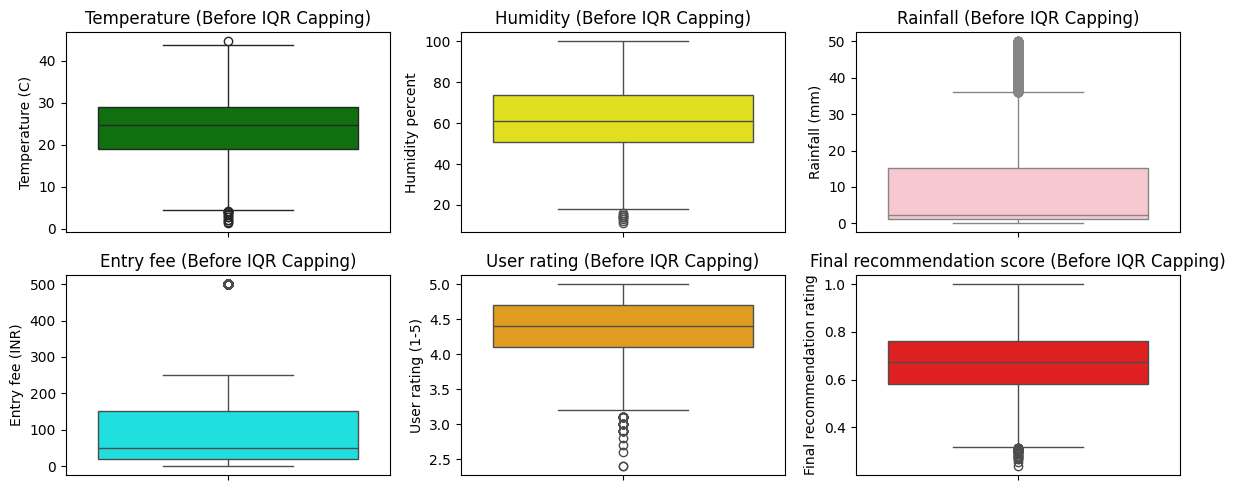

In [91]:
# Made boxplot to show outliers
fig, axes = plt.subplots(2, 3, figsize=(12, 5))

sns.boxplot(y=df['temperature_c'], ax=axes[0,0], color='green')
axes[0,0].set_title('Temperature (Before IQR Capping)')
axes[0,0].set_ylabel('Temperature (C)')

sns.boxplot(y=df['humidity_percent'], ax=axes[0,1], color='yellow')
axes[0,1].set_title('Humidity (Before IQR Capping)')
axes[0,1].set_ylabel('Humidity percent')

sns.boxplot(y=df['rainfall_mm'], ax=axes[0,2], color='pink')
axes[0,2].set_title('Rainfall (Before IQR Capping)')
axes[0,2].set_ylabel('Rainfall (mm)')

sns.boxplot(y=df['entry_fee_inr'], ax=axes[1,0], color='cyan')
axes[1,0].set_title('Entry fee (Before IQR Capping)')
axes[1,0].set_ylabel('Entry fee (INR)')

sns.boxplot(y=df['user_rating'], ax=axes[1,1], color='orange')
axes[1,1].set_title('User rating (Before IQR Capping)')
axes[1,1].set_ylabel('User rating (1-5)')

sns.boxplot(y=df['final_recommendation_score'], ax=axes[1,2], color='red')
axes[1,2].set_title('Final recommendation score (Before IQR Capping)')
axes[1,2].set_ylabel('Final recommendation rating')

plt.tight_layout()
plt.savefig('boxplots.png')
plt.show()
plt.close()

In [92]:
Q1 = df['humidity_percent'].quantile(0.25)         # Correcting outliers
Q3 = df['humidity_percent'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

df['humidity_percent'] = df['humidity_percent'].clip(lower=lower_bound, upper=upper_bound)

In [93]:
Q1 = df['temperature_c'].quantile(0.25)         # Correcting outliers
Q3 = df['temperature_c'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

df['temperature_c'] = df['temperature_c'].clip(lower=lower_bound, upper=upper_bound)

In [94]:
Q1 = df['rainfall_mm'].quantile(0.25)         # Correcting outliers
Q3 = df['rainfall_mm'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

df['rainfall_mm'] = df['rainfall_mm'].clip(lower=lower_bound, upper=upper_bound)

In [95]:
Q1 = df['entry_fee_inr'].quantile(0.25)         # Correcting outliers
Q3 = df['entry_fee_inr'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

df['entry_fee_inr'] = df['entry_fee_inr'].clip(lower=lower_bound, upper=upper_bound)

In [96]:
Q1 = df['user_rating'].quantile(0.25)         # Correcting outliers
Q3 = df['user_rating'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

df['user_rating'] = df['user_rating'].clip(lower=lower_bound, upper=upper_bound)

In [97]:
Q1 = df['final_recommendation_score'].quantile(0.25)         # Correcting outliers
Q3 = df['final_recommendation_score'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

df['final_recommendation_score'] = df['final_recommendation_score'].clip(lower=lower_bound, upper=upper_bound)

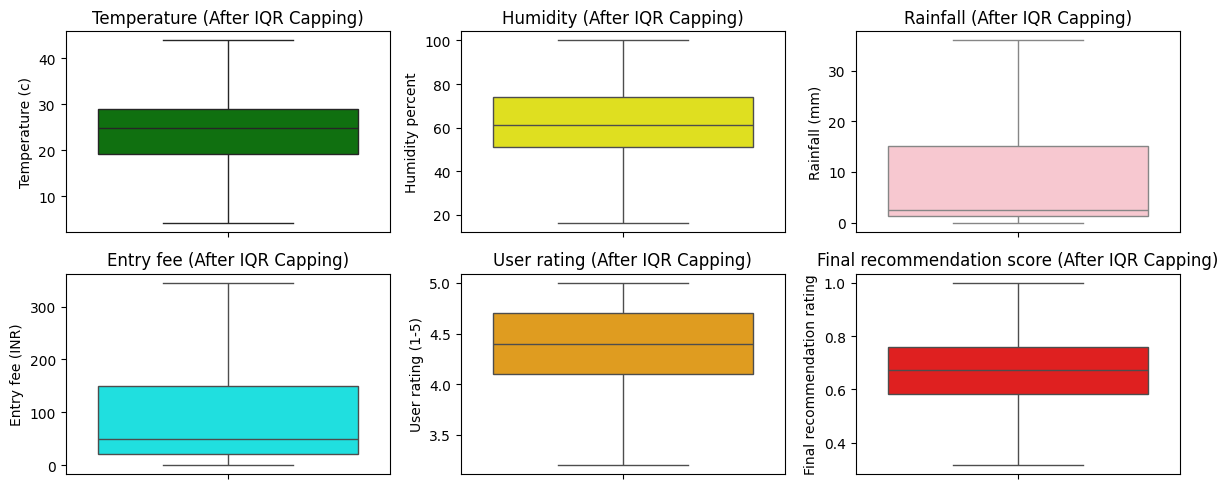

In [98]:
# Made boxplot after correcting outliers
fig, axes = plt.subplots(2, 3, figsize=(12, 5))

sns.boxplot(y=df['temperature_c'], ax=axes[0,0], color='green')
axes[0,0].set_title('Temperature (After IQR Capping)')
axes[0,0].set_ylabel('Temperature (c)')

sns.boxplot(y=df['humidity_percent'], ax=axes[0,1], color='yellow')
axes[0,1].set_title('Humidity (After IQR Capping)')
axes[0,1].set_ylabel('Humidity percent')

sns.boxplot(y=df['rainfall_mm'], ax=axes[0,2], color='pink')
axes[0,2].set_title('Rainfall (After IQR Capping)')
axes[0,2].set_ylabel('Rainfall (mm)')

sns.boxplot(y=df['entry_fee_inr'], ax=axes[1,0], color='cyan')
axes[1,0].set_title('Entry fee (After IQR Capping)')
axes[1,0].set_ylabel('Entry fee (INR)')

sns.boxplot(y=df['user_rating'], ax=axes[1,1], color='orange')
axes[1,1].set_title('User rating (After IQR Capping)')
axes[1,1].set_ylabel('User rating (1-5)')

sns.boxplot(y=df['final_recommendation_score'], ax=axes[1,2], color='red')
axes[1,2].set_title('Final recommendation score (After IQR Capping)')
axes[1,2].set_ylabel('Final recommendation rating')

plt.tight_layout()
plt.savefig('boxplots.png')
plt.show()
plt.close()

In [99]:
# Label encoding
is_weekend_map = {'Yes': 1, 'No': 0}
df["is_weekend"] = df["is_weekend"].map(is_weekend_map)

entry_free_map = {'Yes': 1, 'No': 0}
df["entry_free"] = df["entry_free"].map(entry_free_map)

would_revisit_map = {'Yes': 1, 'No': 0}
df["would_revisit"] = df["would_revisit"].map(would_revisit_map)

would_recommend_map = {'Yes': 1, 'No': 0}
df["would_recommend"] = df["would_recommend"].map(would_recommend_map)

In [100]:
# Min-Max normalization
scaler = MinMaxScaler()
df["sentiment_score"] = scaler.fit_transform(df[["sentiment_score"]])
df["weather_suitability_score"] = scaler.fit_transform(df[["weather_suitability_score"]])

In [101]:
# Changing datatypes
df["crowd_numeric"] = df["crowd_numeric"].astype(int)
df["entry_fee_inr"] = df["entry_fee_inr"].astype(int)
df["is_weekend"] = df["is_weekend"].astype(str)
df['visit_date'] = pd.to_datetime(df['visit_date'], format='%d-%m-%Y')

In [102]:
df.dtypes

,0
row_id,int64
place_id,object
place_name,object
city,object
state,object
category,object
latitude,float64
longitude,float64
visit_date,datetime64[ns]
visit_year,int64


In [103]:
df.to_csv("cleaned_indian_tourist_places_dataset.csv", index=False)

In [104]:
from google.colab import files

files.download('cleaned_indian_tourist_places_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Tourist Count =>**

In [105]:
# Year-wise visits
yearly_count = df.groupby('visit_year').size().reset_index(name='visit_count')

In [106]:
yearly_count

,visit_year,visit_count
0,2019,2129
1,2020,2176
2,2021,2144
3,2022,2205
4,2023,2170
5,2024,2176


In [107]:
# Year-wise and season-wise visits
yearly_season_count = df.groupby(['visit_year', 'season']).size().reset_index(name='visit_count')

In [108]:
yearly_season_count

,visit_year,season,visit_count
0,2019,Monsoon,715
1,2019,Spring,509
2,2019,Summer,324
3,2019,Winter,581
4,2020,Monsoon,724
5,2020,Spring,541
6,2020,Summer,368
7,2020,Winter,543
8,2021,Monsoon,684
9,2021,Spring,554


In [109]:
# Month-wise visits from year 2019-2024
monthly_count = df.groupby('visit_month_name').size().reset_index(name='visit_count')

In [110]:
monthly_count

,visit_month_name,visit_count
0,April,1090
1,August,1050
2,December,1111
3,February,1026
4,January,1111
5,July,1109
6,June,1039
7,March,1069
8,May,1076
9,November,1131


# **Exploratory Data Analysis and Visualization =>**

In [111]:
df[['user_rating', 'entry_fee_inr',
    'temperature_c', 'rainfall_mm',
    'humidity_percent',
    'weather_suitability_score',
    'final_recommendation_score']].describe().T

,count,mean,std,min,25%,50%,75%,max
user_rating,13000.0,4.379300,0.412799,3.20000,4.100000,4.400000,4.700,5.0000
entry_fee_inr,13000.0,92.606538,102.983011,0.00000,20.000000,50.000000,150.000,345.0000
temperature_c,13000.0,23.987954,7.028772,4.25000,19.100000,24.800000,29.000,43.8500
rainfall_mm,13000.0,9.220049,12.510257,0.00000,1.200000,2.400000,15.125,36.0125
humidity_percent,13000.0,62.355654,15.988599,16.50000,51.000000,61.000000,74.000,100.0000
weather_suitability_score,13000.0,0.560347,0.282348,0.00000,0.344444,0.588889,0.800,1.0000
final_recommendation_score,13000.0,0.668745,0.129250,0.31625,0.582500,0.672500,0.760,1.0000


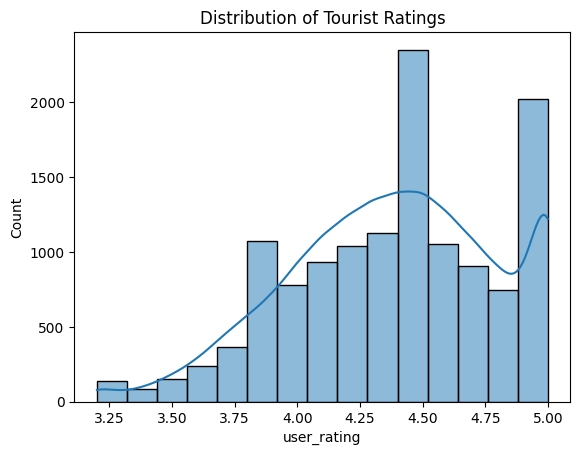

In [112]:
# Histogram for counting user ratings
sns.histplot(data=df, x='user_rating', bins=15, kde=True)
plt.title('Distribution of Tourist Ratings')
plt.show()

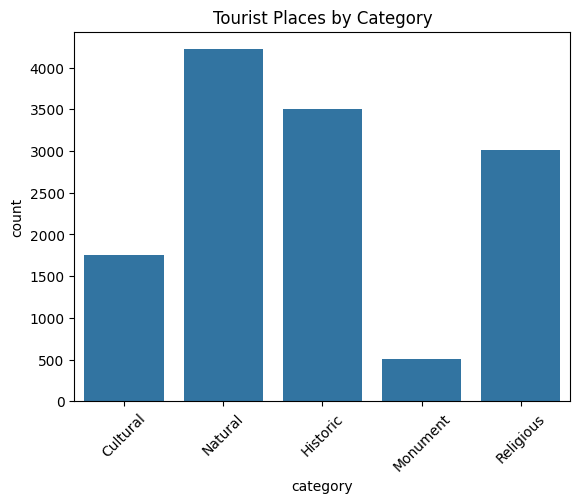

In [113]:
# Bar Chart for counting categories
sns.countplot(data=df, x='category')
plt.title('Tourist Places by Category')
plt.xticks(rotation=45)
plt.show()

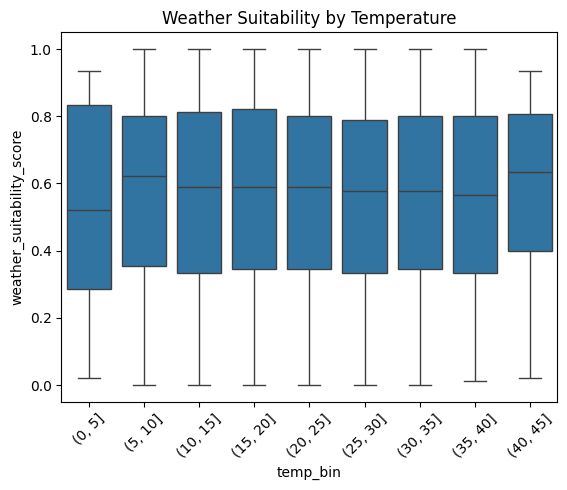

In [114]:
# Boxplot for weather suitability by temperature
df['temp_bin'] = pd.cut(df['temperature_c'], bins=range(0, 50, 5))

sns.boxplot(data=df, x='temp_bin', y='weather_suitability_score')
plt.title('Weather Suitability by Temperature')
plt.xticks(rotation=45)
plt.show()

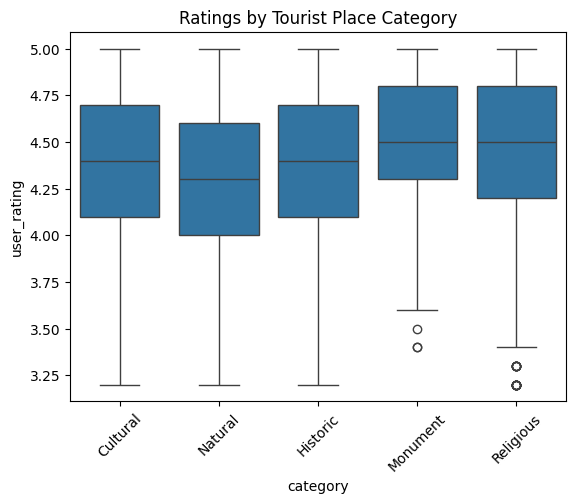

In [115]:
# Boxplot for category-wise user rating
sns.boxplot(data=df, x='category', y='user_rating')
plt.title('Ratings by Tourist Place Category')
plt.xticks(rotation=45)
plt.show()

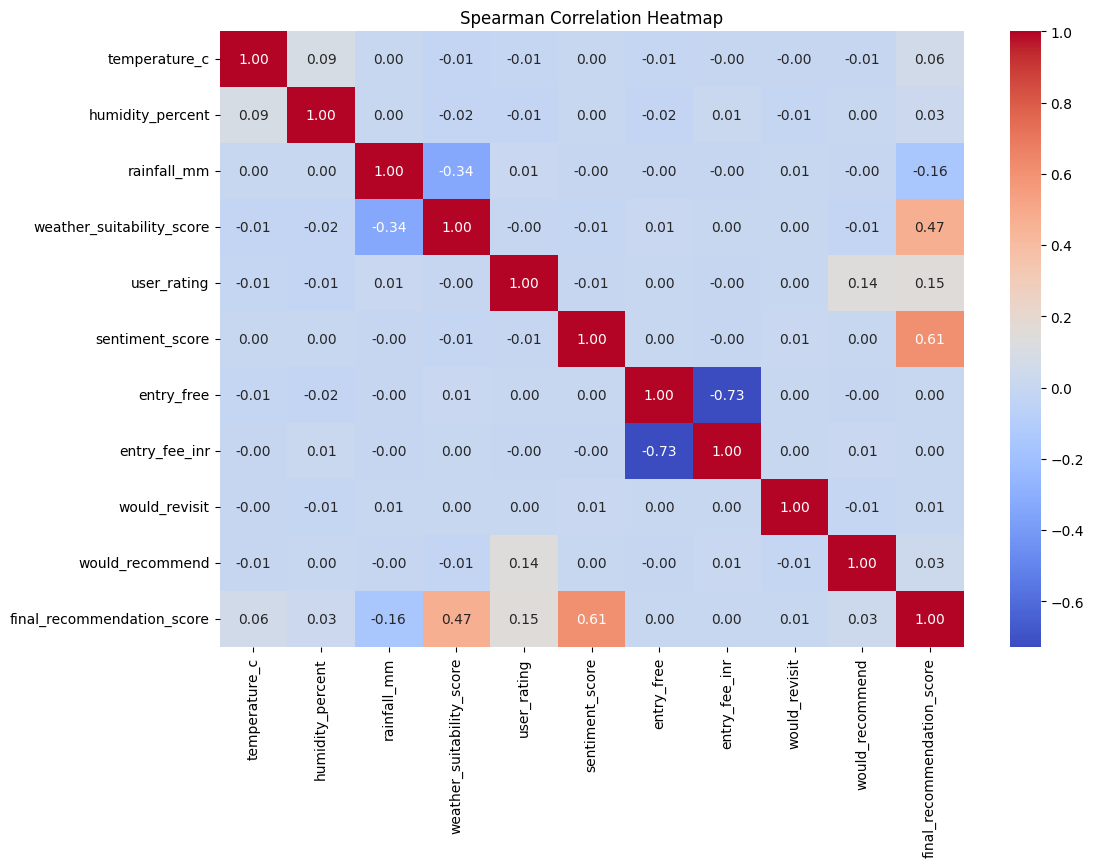

In [116]:
# Correlation heatmap of numerical columns
numeric_df = df.select_dtypes(include='number').drop(
    columns=['row_id', 'latitude', 'longitude',
             'visit_year', 'visit_month', 'crowd_numeric'],
    errors='ignore'
)

corr = numeric_df.corr(method='spearman')

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Spearman Correlation Heatmap')
plt.show()

In [117]:
# Group-wise comparison of user rating by state
state_rating = df.groupby('state')['user_rating'].agg(['count', 'mean', 'median']).round(2)

print(state_rating.sort_values('mean', ascending=False))

                  count  mean  median
state                                
Punjab              897  4.51     4.6
Delhi               855  4.49     4.5
Uttar Pradesh      1072  4.46     4.5
Jammu & Kashmir    1053  4.45     4.5
West Bengal        1039  4.45     4.5
Maharashtra        1049  4.38     4.4
Telangana          1052  4.38     4.4
Karnataka          1060  4.37     4.4
Rajasthan          1053  4.36     4.4
Kerala              876  4.33     4.4
Himachal Pradesh   1077  4.28     4.3
Tamil Nadu         1917  4.25     4.3


In [118]:
# Group-wise comparison of user rating by category
category_rating = df.groupby('category')['user_rating'].agg(['count', 'mean', 'median']).round(2)

print(category_rating.sort_values('mean', ascending=False))

           count  mean  median
category                      
Monument     510  4.53     4.5
Religious   3013  4.46     4.5
Historic    3507  4.40     4.4
Cultural    1750  4.35     4.4
Natural     4220  4.30     4.3


In [119]:
# Group-wise comparison of weather suitability score by season
season_score = df.groupby('season')['weather_suitability_score'].agg(['count', 'mean', 'median']).round(3)

print(season_score.sort_values('mean', ascending=False))

         count   mean  median
season                       
Winter    3361  0.566   0.589
Summer    2137  0.562   0.578
Spring    3235  0.560   0.589
Monsoon   4267  0.555   0.578


In [120]:
# Group-wise comparison of user rating by is_weekend (if it is a weekend or not)
print(df.groupby('is_weekend')['user_rating'].agg(['count', 'mean', 'median']).round(2))

            count  mean  median
is_weekend                     
0            9216  4.38     4.4
1            3784  4.38     4.4


In [121]:
# Categorical Analysis
print(df['would_recommend'].value_counts())
print(df['would_recommend'].value_counts(normalize=True).mul(100).round(2))

would_recommend
1    12906
0       94
Name: count, dtype: int64
would_recommend
1    99.28
0     0.72
Name: proportion, dtype: float64


In [122]:
print(df['travel_type'].value_counts())

travel_type
Group       2819
Solo        2612
Family      2555
Couple      2521
Business    2493
Name: count, dtype: int64


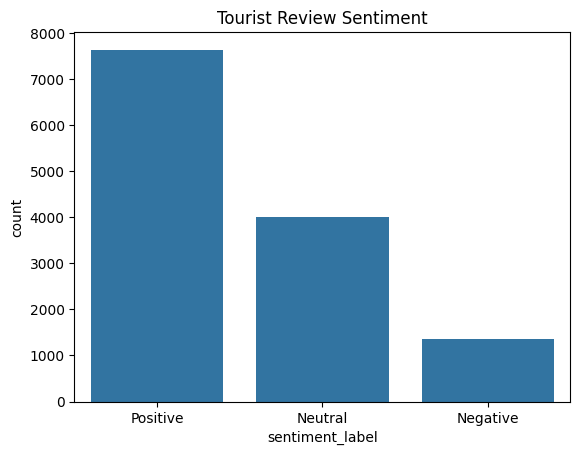

In [123]:
# Bar Chart for counting sentiment label
sns.countplot(data=df, x='sentiment_label')
plt.title('Tourist Review Sentiment')
plt.show()

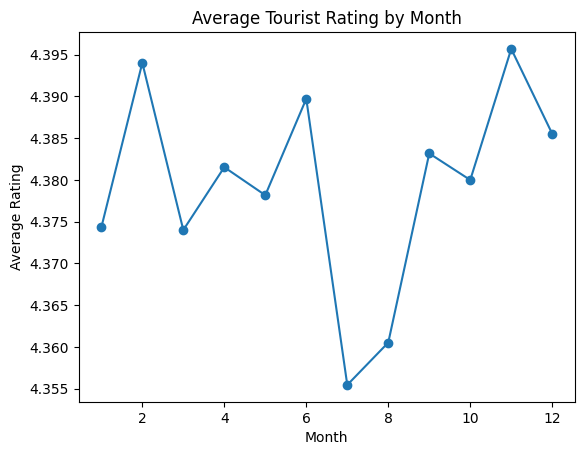

In [124]:
# Line graph of average tourist rating by month
monthly_rating = df.groupby('visit_month')['user_rating'].mean()

monthly_rating.plot(kind='line', marker='o')
plt.title('Average Tourist Rating by Month')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.show()

# **Tourist Footfall Trend =>**

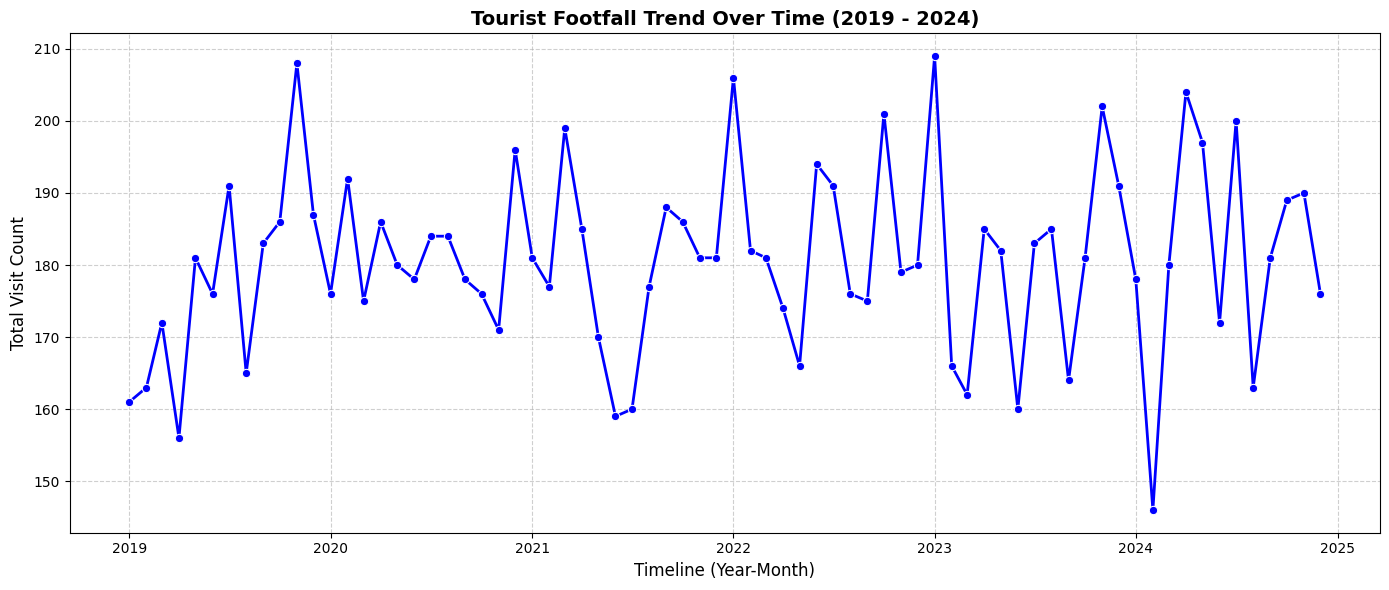

In [125]:
# Time series trend by year-month
df['year_month'] = pd.to_datetime(df['visit_date']).dt.to_period('M')
monthly_footfall = df.groupby('year_month').size().reset_index(name='visit_count')
monthly_footfall['year_month'] = monthly_footfall['year_month'].dt.to_timestamp()

plt.figure(figsize=(14, 6))
sns.lineplot(
    data=monthly_footfall,
    x='year_month',
    y='visit_count',
    marker='o',
    color='b',
    linewidth=2
)

plt.title('Tourist Footfall Trend Over Time (2019 - 2024)', fontsize=14, fontweight='bold')
plt.xlabel('Timeline (Year-Month)', fontsize=12)
plt.ylabel('Total Visit Count', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()